# **my project :**
# Reducing costs and improving productivity.


 

In [19]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score,mean_squared_error
from scipy.sparse.csgraph import shortest_path
from scipy.sparse import csr_matrix

print("All libraries imported !")

All libraries imported !


In [20]:
# database connection
conn = sqlite3.Connection("E:/pythonn/supply_chain_project/project_asmaa.db")
cursor =conn.cursor()


# create table

cursor.executescript (""" 
    CREATE TABLE IF NOT EXISTS factories(
        id         INTEGER PRIMARY KEY,
        name       TEXT,
        capacity   INTEGER,
        location   TEXT
    );
    CREATE TABLE IF NOT EXISTS products(
        id         INTEGER PRIMARY KEY, 
        name       TEXT , 
        price      REAL
    );
    CREATE TABLE IF NOT EXISTS stores(          
        id          INTEGER PRIMARY KEY,  
        name        TEXT,
        demand      INTEGER ,
        location    TEXT
    );
    CREATE TABLE IF NOT EXISTS sales(             
        id               INTEGER PRIMARY KEY,              
        store_id         INTEGER              , 
        product_id       INTEGER             , 
        month            INTEGER            , 
        quantity         INTEGER            , 
        revenue          REAL
    );
    CREATE TABLE IF NOT EXISTS transport_cost(  
        factory_id        INTEGER, 
        store_id          INTEGER, 
        cost              REAL
    );
    CREATE TABLE IF NOT EXISTS shortest_path(  
        id                INTEGER PRIMARY KEY, 
        factory_id        INTEGER ,       
        store_id          INTEGER, 
        distance          REAL
    );   
    CREATE TABLE IF NOT EXISTS production_plan( 
        id                    INTEGER PRIMARY KEY,    
        factory_id            INTEGER, 
        product_id            INTEGER, 
        quantity              INTEGER,  
        cost                  REAL, 
        energy                REAL
    );
""")

conn.commit()
# delete existing data before inserting
cursor.executescript("""
    DELETE FROM factories;
    DELETE FROM products;
    DELETE FROM stores;
    DELETE FROM sales;
    DELETE FROM transport_cost;
    DELETE FROM shortest_path;
    DELETE FROM production_plan;
""")
conn.commit()
print("Database created !")

Database created !


In [21]:
# Insert data
cursor.executescript(""" 
     INSERT OR IGNORE INTO factories VALUES
          (1,'Alfatron_Factory',120,'oran'),
          (2,'SARL_BATELEC'    ,200,'Bejaia'),
          (3,'Eurl_Divatech'   ,160,'Algiers');
     
     INSERT OR IGNORE INTO  products VALUES
          (1,'computer',8000),
          (2,'Mouse'   ,150),
          (3,'Keyboard',300),
          (4,'Monitor', 2500);
     
     INSERT OR IGNORE INTO  stores VALUES 
          (1,'TechZone'     ,86, 'Constantine'),
          (2,'InfoPoint'    ,100 ,'Sétif'),
          (3,'Digital_Store',110,'Annaba'),
          (4,'Electro_Shop' ,96, 'Tlemcen'),
          (5,'PC_House'     ,80, 'Batna');
     
     INSERT OR IGNORE INTO  sales VALUES
          (1,1,1,1,55,12000), (2,1,1,2,60,13000),(3,1,1,3,58,18000), (4,1,1,4,65,15000),(5,1,1,5,70,16700), (6,1,1,6,68,17900),
          (7,1,2,1,100,1500), (8,1,2,2,65,7800), (9,1,2,3,89,2000), (10,1,2,4,90,1500),(11,1,2,5,89,7000),  (12,1,2,6,56,6800),
          (13,1,3,1,89,1546), (14,1,3,2,70,2378), (15,1,3,3,55,5000), (16,1,3,4,95,2700),(17,1,3,5,78,9800), (18,1,3,6,78,5600),
          (19,1,4,1,56,9876), (20,1,4,2,80,6789), (21,1,4,3,65,6980), (22,1,4,4,60,4300),(23,1,4,5,84,7800), (24,1,4,6,90,7800),
          (25,2,1,1,74,7650), (26,2,1,2,64,9876), (27,2,1,3,59,2500), (28,2,1,4,69,6700),(29,2,1,5,99,4800), (30,2,1,6,65,9000),
          (31,2,2,1,60,8700), (32,2,2,2,78,1000), (33,2,2,3,84,6700), (34,2,2,4,70,5600),(35,2,2,5,65,5600), (36,2,2,6,67,6500),
          (37,2,3,1,78,5326), (38,2,3,2,90,2000), (39,2,3,3,73,7000), (40,2,3,4,67,6750),(41,2,3,5,30,9900), (42,2,3,6,83,6700),
          (43,2,4,1,85,9765), (44,2,4,2,89,3000), (45,2,4,3,67,7500), (46,2,4,4,50,6000),(47,2,4,5,45,3000), (48,2,4,6,93,8300),
          (49,3,1,1,54,1000), (50,3,1,2,75,6500), (51,3,1,3,89,4000), (52,3,1,4,85,8900),(53,3,1,5,78,5400), (54,3,1,6,75,9300),
          (55,3,2,1,72,7658), (56,3,2,2,53,6000), (57,3,2,3,98,2000), (58,3,2,4,88,6700),(59,3,2,5,29,7800), (60,3,2,6,90,7500),
          (61,3,3,1,90,9758), (62,3,3,2,59,7000), (63,3,3,3,56,1250), (64,3,3,4,71,9800),(65,3,3,5,89,2900), (66,3,3,6,67,9000),
          (67,3,4,1,93,2313), (68,3,4,2,99,8000), (69,3,4,3,65,7890), (70,3,4,4,82,6700),(71,3,4,5,60,9800), (72,3,4,6,90,6700),
          (73,4,1,1,96,6854), (74,4,1,2,67,9000), (75,4,1,3,76,8000), (76,4,1,4,93,8200),(77,4,1,5,50,5000), (78,4,1,6,67,6000),
          (79,4,2,1,89,6797), (80,4,2,2,79,6050), (81,4,2,3,86,4000), (82,4,2,4,54,9300),(83,4,2,5,40,6000), (84,4,2,6,56,7600),
          (85,4,3,1,78,9800), (86,4,3,2,45,7654), (87,4,3,3,96,6000), (88,4,3,4,77,5400),(89,4,3,5,89,4000), (90,4,3,6,66,5600),
          (91,4,4,1,93,7543), (92,4,4,2,89,1233), (93,4,4,3,74,8900), (94,4,4,4,55,7700),(95,4,4,5,90,8900), (96,4,4,6,76,6600),
          (97,5,1,1,84,8754), (98,5,1,2,36,1246), (99,5,1,3,76,6543), (100,5,1,4,92,5500),(101,5,1,5,78,9000),(102,5,1,6,64,6400),
          (103,5,2,1,66,6000), (104,5,2,2,66,5643), (105,5,2,3,84,4800), (106,5,2,4,83,9300),(107,5,2,5,87,7800),(108,5,2,6,66,8000),
          (109,5,3,1,77,3421), (110,5,3,2,90,9876), (111,5,3,3,88,2700), (112,5,3,4,74,8400),(113,5,3,5,73,8700),(114,5,3,6,56,7800),
          (115,5,4,1,88,6754), (116,5,4,2,67,8745), (117,5,4,3,50,5400), (118,5,4,4,76,5700),(119,5,4,5,87,7300),(120,5,4,6,46,5600);

     INSERT OR IGNORE INTO  transport_cost VALUES
          (1,1,2), (1,2,3), (1,3,1), (1,4,4),(1,5,6),
          (2,1,5), (2,2,4), (2,3,8), (2,4,2),(2,5,9),
          (3,1,3), (3,2,6), (3,3,2), (3,4,7) ,(3,5,8);

     INSERT OR IGNORE INTO shortest_path VALUES
          (1,1,1,350.5), (2,1,2,250), (3,1,3,590), (4,1,4,400),(5,1,5,600),
          (6,2,1,600), (7,2,2,420), (8,2,3,200), (9,2,4,530.45),(10,2,5,960),
          (11,3,1,140), (12,3,2,500), (13,3,3,300.6), (14,3,4,700),(15,3,5,690);

     INSERT OR IGNORE INTO  production_plan VALUES
          (1,1,1,50,375000,1200),  (2,1,2,200,30000,300),
          (3,1,3,150,45000,400),   (4,1,4,80,200000,900),
          (5,2,1,80,600000,1800),  (6,2,2,300,45000,450),
          (7,2,3,200,60000,550),   (8,2,4,120,300000,1200),
          (9,3,1,60,450000,1500),  (10,3,2,250,37500,350),
          (11,3,3,180,54000,480),   (12,3,4,100,250000,1000)                              
     """)
conn.commit()
print(" Data inserted!")

 Data inserted!


In [22]:
# Display all data
df_factories =  pd.read_sql("SELECT * FROM factories ",conn)
df_stores =     pd.read_sql("SELECT * FROM stores",conn)
df_costs =      pd.read_sql("SELECT * FROM transport_cost",conn)
df_path =       pd.read_sql("SELECT * FROM shortest_path ",conn)
df_sales =      pd.read_sql("SELECT * FROM sales ",conn)
df_PrPlan=      pd.read_sql("SELECT * FROM production_plan ",conn)
df_products=     pd.read_sql("SELECT * FROM  products",conn)
print("-" * 100)
print("               Factories :      ")
print(df_factories)

print("-" * 100 )
print("\n              stores           ")
print(df_stores)

print("-" * 100 )
print("\n       Transportation costs    ")
print(df_costs.pivot(index="factory_id", columns="store_id", values="cost"))
print("-" * 100 )

 
print("\n       production_plan    ")
print(df_PrPlan.pivot(index="factory_id", columns="product_id", values="cost"))
print("-" * 100 )
print(df_PrPlan.pivot(index="factory_id", columns="product_id", values="quantity"))
print(df_PrPlan.pivot(index="factory_id", columns="product_id", values="energy"))

print("\n       shortest_path    ")
print(df_path.pivot(index="factory_id", columns="store_id", values="distance"))
print("-" * 100 )

print("\n       products    ")
print(df_products)






----------------------------------------------------------------------------------------------------
               Factories :      
   id              name  capacity location
0   1  Alfatron_Factory       120     oran
1   2      SARL_BATELEC       200   Bejaia
2   3     Eurl_Divatech       160  Algiers
----------------------------------------------------------------------------------------------------

              stores           
   id           name  demand     location
0   1       TechZone      86  Constantine
1   2      InfoPoint     100        Sétif
2   3  Digital_Store     110       Annaba
3   4   Electro_Shop      96      Tlemcen
4   5       PC_House      80        Batna
----------------------------------------------------------------------------------------------------

       Transportation costs    
store_id      1    2    3    4    5
factory_id                         
1           2.0  3.0  1.0  4.0  6.0
2           5.0  4.0  8.0  2.0  9.0
3           3.0  6.0  2.0  7.0

In [23]:
# Demand Forecasting with Linear Regression
# Train model for each store
print("=== Demand Forecast (Month 7) ===")
foricasts = {}
for store_id in range (1,6):
    df_store = df_sales[df_sales["store_id"] == store_id]
    X = df_store[["month"]]
    y = df_store["quantity"]

    model = LinearRegression()
    model.fit(X,y)
    forecast = model.predict(pd.DataFrame([[7]], columns=["month"]))[0]
    foricasts[store_id]= round(forecast,1)
    r2=r2_score(y,model.predict(X))
    print(f"Store_{store_id}: forecast={round(forecast,1)} units (R²={round(r2,2)})")


=== Demand Forecast (Month 7) ===
Store_1: forecast=77.1 units (R²=0.01)
Store_2: forecast=65.6 units (R²=0.03)


Store_3: forecast=75.1 units (R²=0.0)
Store_4: forecast=60.7 units (R²=0.16)
Store_5: forecast=68.3 units (R²=0.03)


In [24]:
# Transportation Problem - Minimize cost
supply = df_factories["capacity"].tolist()  
demand = df_stores["demand"].tolist()        
costs  = df_costs.pivot(index="factory_id", 
                        columns="store_id", 
                        values="cost").values.flatten()

# Build constraints
c = costs  # minimize total cost

# Supply constraints
A_supply = []
for i in range(3):
    row = [0] * 15
    for j in range(5):
        row[i*5 + j] = 1
    A_supply.append(row)

# Demand constraints
A_demand = []
for j in range(5):
    row = [0] * 15
    for i in range(3):
        row[i*5 + j] = -1
    A_demand.append(row)

A = A_supply + A_demand
b = supply + [-d for d in demand]

result = linprog(c, A_ub=A, b_ub=b, bounds=[(0,None)]*15)

print(f" Min Transport Cost: {round(result.fun, 2)}")

# Display results
x = result.x.reshape(3, 5).round(1)

df_result = pd.DataFrame(x,
    index=["Alfatron","SARL_BATELEC","Eurl_Divatech"],
    columns=["TechZone","InfoPoint","Digital_Store","Electro_Shop","PC_House"])

print("\n=== Optimal Distribution ===")
print(df_result)

 Min Transport Cost: 1510.0

=== Optimal Distribution ===
               TechZone  InfoPoint  Digital_Store  Electro_Shop  PC_House
Alfatron            0.0        0.0           40.0           0.0      80.0
SARL_BATELEC        0.0      100.0            0.0          96.0       0.0
Eurl_Divatech      86.0        0.0           70.0           0.0       0.0


In [25]:
# build 8 * 8 distance matrix

n= 8          # 3 factories ( 0,1,2) + 5 stores (3,4,5,6,7)
graph = np.zeros((n,n))

# FIll distances from df_path
for _ ,row in df_path.iterrows():
    f= int(row["factory_id"])-1         #factory index 0,1,2
    s=int(row["store_id"]) -1 +3          # store index  3,4,5,6,7
    graph[f][s] = row["distance"]      
    graph[s][f] = row["distance"]      # symmetric

matrix= csr_matrix (graph)

dist_matrix , predecessors = shortest_path(matrix , directed = False, return_predecessors = True)

print ("\n shortest  path solved !" )
print(f"\n Distance matrix shape : {dist_matrix.shape} ")



 shortest  path solved !

 Distance matrix shape : (8, 8) 


In [26]:
# Find closest factory for each store
# display result

labels = ["Alfatron","SARL_BATELEC","Eurl_Divatech","TechZone","InfoPoint","Digital_Store","Electro_Shop","PC_House"]

df_dist =pd.DataFrame(dist_matrix.round(1),index=labels,columns=labels)
print("\n shortest distance")
print(df_dist)

print("\n closest factory per store")

stores = ["TechZone","InfoPoint","Digital_Store","Electro_Shop","PC_House"]
factories = ["Alfatron","SARL_BATELEC","Eurl_Divatech"]

for store in stores :
    distances = {f:df_dist.loc[f,store] for f in factories}
    closest = min(distances , key= distances.get)
    print(f"{store} -> {closest}  ({distances[closest]}km)")


 shortest distance
               Alfatron  SARL_BATELEC  Eurl_Divatech  TechZone  InfoPoint  \
Alfatron            0.0         670.0          490.5     350.5      250.0   
SARL_BATELEC      670.0           0.0          500.6     600.0      420.0   
Eurl_Divatech     490.5         500.6            0.0     140.0      500.0   
TechZone          350.5         600.0          140.0       0.0      600.5   
InfoPoint         250.0         420.0          500.0     600.5        0.0   
Digital_Store     590.0         200.0          300.6     440.6      620.0   
Electro_Shop      400.0         530.4          700.0     750.5      650.0   
PC_House          600.0         960.0          690.0     830.0      850.0   

               Digital_Store  Electro_Shop  PC_House  
Alfatron               590.0         400.0     600.0  
SARL_BATELEC           200.0         530.4     960.0  
Eurl_Divatech          300.6         700.0     690.0  
TechZone               440.6         750.5     830.0  
InfoPoint  

In [27]:
# Most sold product
best = df_sales.groupby("product_id")["quantity"].sum()

print("total quantity per product")
print (best)
print(f"\n most sold : product_{best.idxmax()} ({best.max()} units)")

print("-"*100)
#best store
best_rev = df_sales.groupby("store_id")["revenue"].sum()
print("=== Total Revenue per store ===")
print(best_rev)
print(f"Best store: Store_{best_rev.idxmax()}")
print("-"*100)
# best month
best_month = df_sales.groupby("month")["revenue"].sum()
print("=== Total Revenue per month ===")
print(best_month)
print(f"Best month: Month_{best_month.idxmax()}")


total quantity per product
product_id
1    2141
2    2199
3    2227
4    2244
Name: quantity, dtype: int64

 most sold : product_4 (2244 units)
----------------------------------------------------------------------------------------------------
=== Total Revenue per store ===
store_id
1    189769.0
2    149867.0
3    153869.0
4    162131.0
5    159382.0
Name: revenue, dtype: float64
Best store: Store_1
----------------------------------------------------------------------------------------------------
=== Total Revenue per month ===
month
1    133015.0
2    122790.0
3    117163.0
4    140150.0
5    147200.0
6    154700.0
Name: revenue, dtype: float64
Best month: Month_6


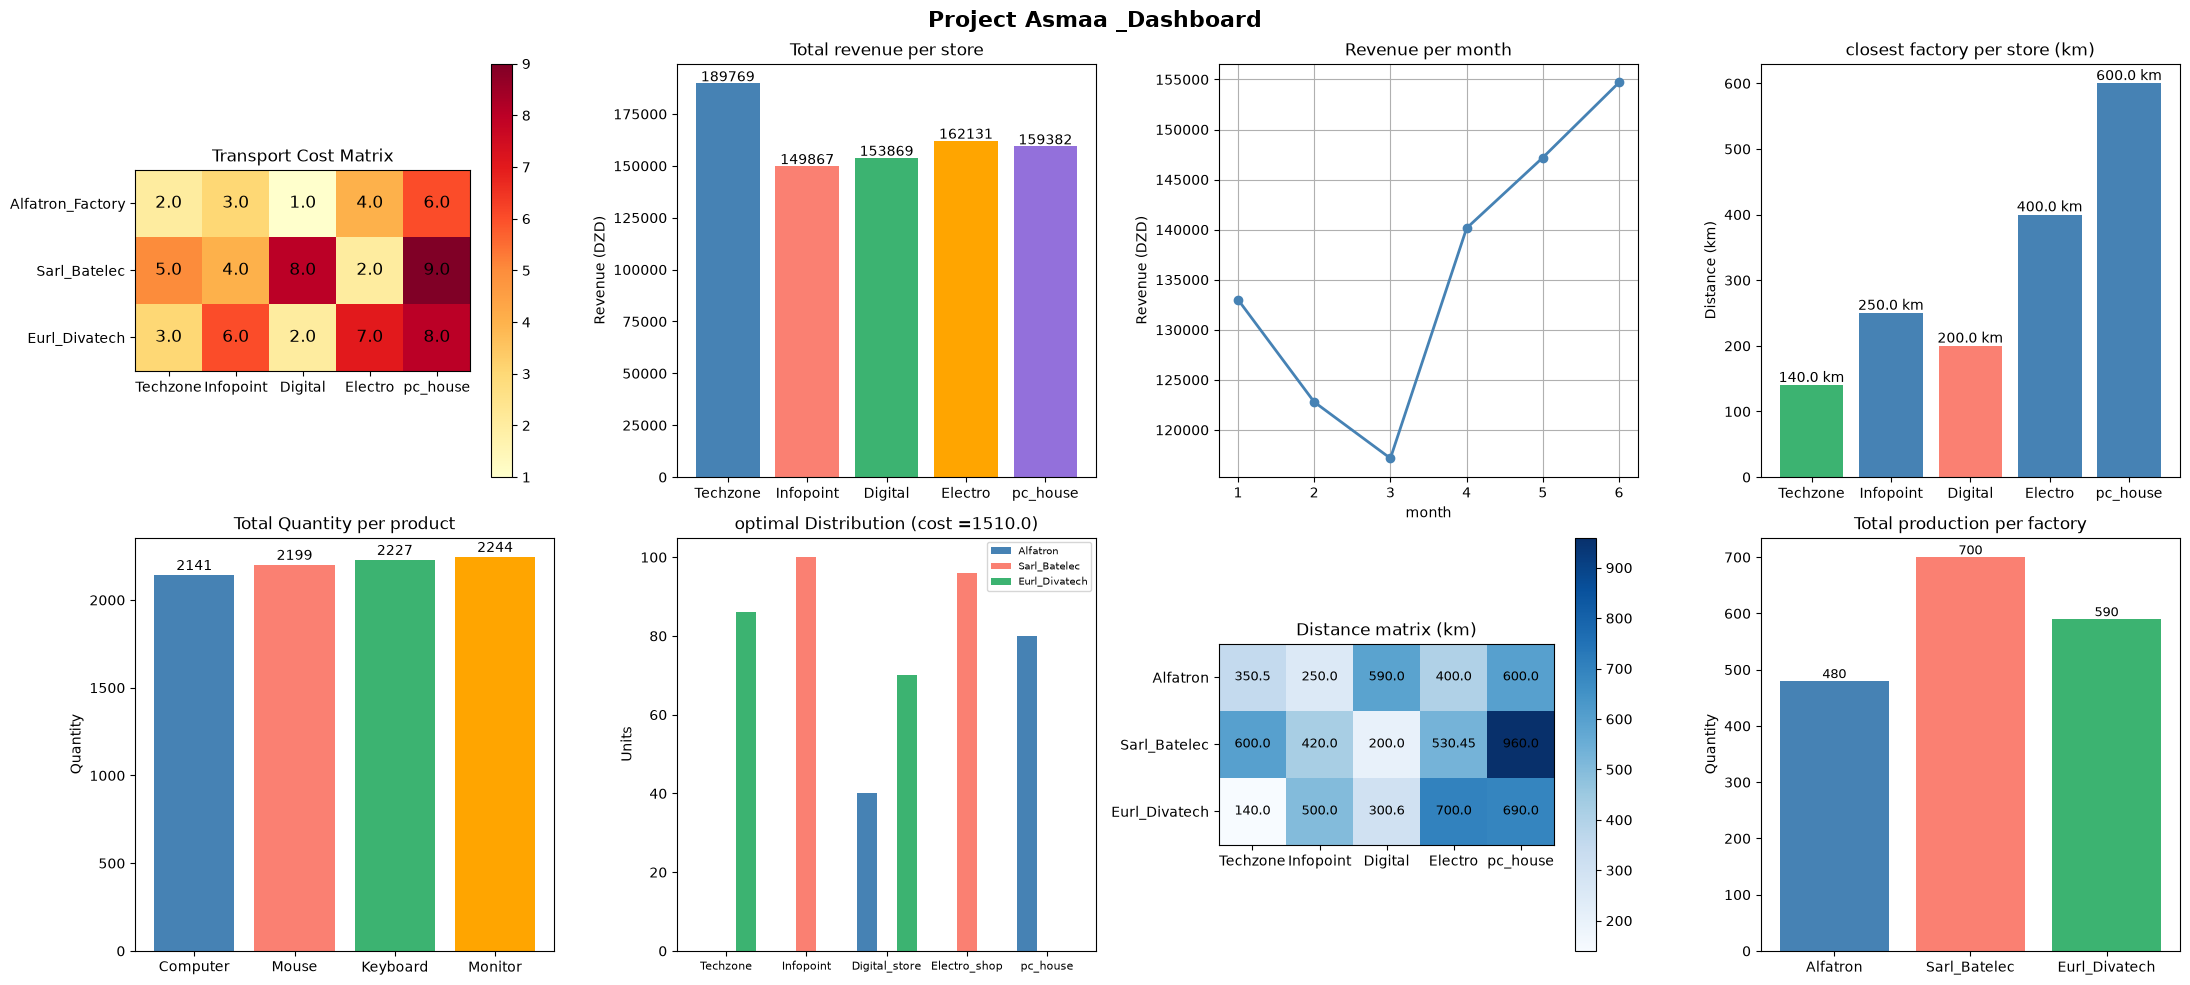

In [28]:
# Visualization
fig, axes = plt.subplots(2, 4, figsize=(22, 10))


# --- 1) Transport cost heatmap ---
ax1 = axes[0, 0]
cost_matrix = df_costs.pivot(index="factory_id", 
                              columns="store_id", 
                              values="cost").values
im = ax1.imshow(cost_matrix, cmap="YlOrRd")
ax1.set_xticks(range(5))
ax1.set_yticks(range(3))
ax1.set_xticklabels(["Techzone","Infopoint","Digital","Electro","pc_house"])
ax1.set_yticklabels(["Alfatron_Factory","Sarl_Batelec","Eurl_Divatech"])
ax1.set_title("Transport Cost Matrix")
for i in range(3):
    for j in range(5):
        ax1.text(j, i, cost_matrix[i,j], ha="center", va="center", fontsize=12)
plt.colorbar(im, ax=ax1)

# 2) Revenue per store
ax2 =  axes[0, 1]
colors = ["steelblue","salmon","mediumseagreen","orange","mediumpurple"]
bars = ax2.bar(["Techzone","Infopoint","Digital","Electro","pc_house"],
               best_rev.values,color=colors)
ax2.set_title("Total revenue per store")
ax2.set_ylabel("Revenue (DZD)")
for bar,val in zip(bars,best_rev.values):
    ax2.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+1000,
             f"{int(val)}",ha="center",fontsize=10)

# 3) Revenue per month
ax3 = axes[0,2]
ax3.plot(range(1,7),best_month.values,marker="o",color="steelblue",linewidth=2)
ax3.set_title("Revenue per month")
ax3.set_xlabel("month")
ax3.set_ylabel("Revenue (DZD)")
ax3.set_xticks(range(1,7))
ax3.grid(True)

# 4) closest factory per store 

ax4 = axes[0,3]
store_names =["Techzone","Infopoint","Digital","Electro","pc_house"]
factory_names = ["Alfatron_Factory","Sarl_Batelec","Eurl_Divatech"]
dist_values = [140.0 , 250.0 , 200.0, 400.0 , 600.0]
bar_colors =["mediumseagreen","steelblue","salmon","steelblue","steelblue"]
bars = ax4.bar(store_names,dist_values,color=bar_colors)
ax4.set_title("closest factory per store (km)")
ax4.set_ylabel("Distance (km)")
for bar,val in zip(bars,dist_values):
    ax4.text(bar.get_x()+bar.get_width()/2,
             bar.get_height() + 5,
             f"{val} km",ha="center",fontsize = 10)

# 5) Quantity per product
ax5 = axes[1,0]
products=["Computer","Mouse","Keyboard","Monitor"]
bars = ax5.bar(products,best.values,color=["steelblue","salmon","mediumseagreen","orange"])
ax5.set_title("Total Quantity per product")
ax5.set_ylabel("Quantity")
for bar,val in zip(bars,best.values):
    ax5.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 30,
             str(val),ha="center",fontsize= 10)


# 6) optimal distribution
ax6 = axes [1,1]
x= np.arange(5)
width = 0.25
ax6.bar(x-width,df_result.iloc[0],width,label="Alfatron",color="steelblue")
ax6.bar(x      ,df_result.iloc[1],width,label="Sarl_Batelec",color="salmon")
ax6.bar(x+width,df_result.iloc[2],width,label="Eurl_Divatech",color="mediumseagreen")
ax6.set_xticks(x)
ax6.set_xticklabels(["Techzone","Infopoint","Digital_store","Electro_shop","pc_house"],fontsize= 8)
ax6.set_title(f"optimal Distribution (cost ={result.fun})")
ax6.set_ylabel("Units")
ax6.legend(fontsize=7)


# 7) Distance heatmap
ax7 = axes[1,2]
dist_heatmap = df_path.pivot(index="factory_id",columns="store_id" ,values="distance").values
im2 = ax7.imshow(dist_heatmap,cmap="Blues")
ax7.set_xticks(range(5))
ax7.set_yticks(range(3))
ax7.set_xticklabels(["Techzone","Infopoint","Digital","Electro","pc_house"])
ax7.set_yticklabels(["Alfatron","Sarl_Batelec","Eurl_Divatech"])
ax7.set_title("Distance matrix (km)")
for i in range(3):
    for j in range(5):
        ax7.text(j,i,dist_heatmap[i,j],ha="center",va="center",fontsize= 9)

plt.colorbar(im2,ax=ax7)

# 8) production plan
ax8 = axes[1,3]
df_prod = df_PrPlan.groupby("factory_id")["quantity"].sum()
ax8.bar(["Alfatron","Sarl_Batelec","Eurl_Divatech"],df_prod.values,
        color=["steelblue","salmon","mediumseagreen"])

ax8.set_title("Total production per factory")
ax8.set_ylabel("Quantity")
for i,val in enumerate(df_prod.values):
    ax8.text(i,val + 5,str(val),ha="center",fontsize=9)

plt.suptitle("Project Asmaa _Dashboard",fontsize=16,fontweight="bold")


plt.tight_layout()
plt.show()



In [29]:
# Final Summary
print("=" * 60)
print("   PROJECT ASMAA - FINAL SUMMARY")
print("=" * 60)
print(f"\n📦 Factories : {len(df_factories)}")
print(f"🏪 Stores    : {len(df_stores)}")
print(f"📦 Products  : {len(df_products)}")

print(f"\n🚚 Min Transport Cost : {result.fun} DZD")
print(f"🏆 Most sold product  : Product_{best.idxmax()} ({best.max()} units)")
print(f"💰 Best store         : Store_{best_rev.idxmax()}")
print(f"📅 Best month         : Month_{best_month.idxmax()}")

print(f"\n📍 Closest factories:")
stores    = ["TechZone","InfoPoint","Digital_Store","Electro_Shop","PC_House"]
factories = ["Alfatron","SARL_BATELEC","Eurl_Divatech"]
for store in stores:
    distances = {f: df_dist.loc[f, store] for f in factories}
    closest   = min(distances, key=distances.get)
    print(f"   {store} → {closest} ({distances[closest]} km)")

print("\n✅ System ready!")
print("=" * 60)

conn.close()
print("\n🔒 Database closed!")

   PROJECT ASMAA - FINAL SUMMARY

📦 Factories : 3
🏪 Stores    : 5
📦 Products  : 4

🚚 Min Transport Cost : 1510.0 DZD
🏆 Most sold product  : Product_4 (2244 units)
💰 Best store         : Store_1
📅 Best month         : Month_6

📍 Closest factories:
   TechZone → Eurl_Divatech (140.0 km)
   InfoPoint → Alfatron (250.0 km)
   Digital_Store → SARL_BATELEC (200.0 km)
   Electro_Shop → Alfatron (400.0 km)
   PC_House → Alfatron (600.0 km)

✅ System ready!

🔒 Database closed!
